Априорная оценка количества итераций: 12
Номер последней итерации: 5
Апостериорная погрешность: 9.60e-04
x(0) = -5.000000, точное: -5.000000
x(1) = -7.046746, точное: -7.046919


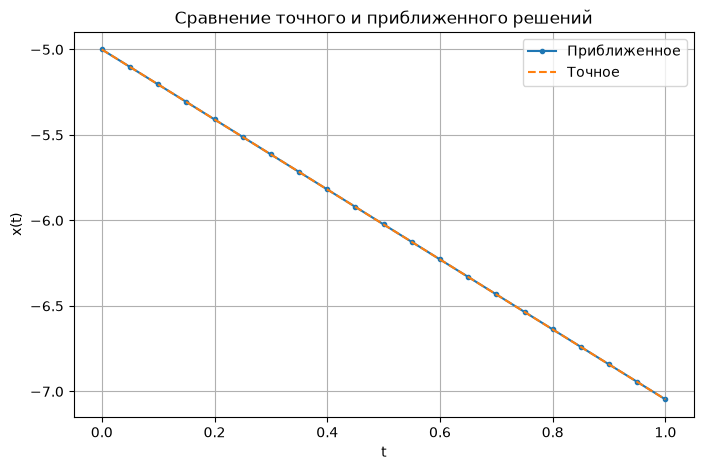

In [3]:
import math
import matplotlib.pyplot as plt

def K(t, s):
    return t / (1 + s)

def Simpson(funcVals, h):
    n = len(funcVals) - 1
    s = funcVals[0] + funcVals[n]
    for i in range(1, n, 2):
        s += 4 * funcVals[i]
    for i in range(2, n, 2):
        s += 2 * funcVals[i]
    return (h / 3) * s

def ExactSolution(t):
    C = (-5 * math.log(2)) / (0.5 + 0.5 * math.log(2))
    return 0.5 * C * t - 5

def main():
    a, b = 0.0, 1.0
    h = 0.05
    e = 1e-3
    lam = 0.5
    alpha = 0.5

    tVals = [a + i * h for i in range(int((b - a) / h) + 1)]
    sVals = tVals.copy()

    xPrev = [-5.0] * len(tVals)

    x1Est = []
    for t in tVals:
        fVals = [K(t, s) * xPrev[j] for j, s in enumerate(sVals)]
        integral = Simpson(fVals, h)
        x1Est.append(lam * integral - 5)

    diff01 = max(abs(x1Est[i] - xPrev[i]) for i in range(len(tVals)))
    nApr = math.floor(math.log(e * (1 - alpha) / diff01) / math.log(alpha)) + 1
    print(f"Априорная оценка количества итераций: {nApr}")

    n = 0
    while True:
        n += 1
        xNext = []
        for t in tVals:
            fVals = [K(t, s) * xPrev[j] for j, s in enumerate(sVals)]
            integral = Simpson(fVals, h)
            xNext.append(lam * integral - 5)

        diff = max(abs(xNext[i] - xPrev[i]) for i in range(len(tVals)))
        aPostErr = (alpha / (1 - alpha)) * diff

        if aPostErr <= e:
            break
        xPrev = xNext.copy()

    print(f"Номер последней итерации: {n}")
    print(f"Апостериорная погрешность: {aPostErr:.2e}")
    print(f"x(0) = {xNext[0]:.6f}, точное: {ExactSolution(0):.6f}")
    print(f"x(1) = {xNext[-1]:.6f}, точное: {ExactSolution(1):.6f}")

    yExact = [ExactSolution(t) for t in tVals]

    plt.figure(figsize=(8, 5))
    plt.plot(tVals, xNext, marker='o', markersize=3, label="Приближенное")
    plt.plot(tVals, yExact, linestyle='--', label="Точное")
    plt.title("Сравнение точного и приближенного решений")
    plt.xlabel("t")
    plt.ylabel("x(t)")
    plt.grid(True)
    plt.legend()
    plt.show()

main()